# 26 · Which properties move each coordinate?

Match every perturbed query to its clean version and retain the same candidate gallery. Measure changes in target distance and changes in the closest-impostor margin. The first estimates sensitivity to a known intervention. The second measures whether that intervention makes the target easier or harder to retrieve.

A pure shift raises mean exact-source distance by 0.488 for fixed local Q and 0.028 for aligned local Q. A gain of 0.55 gives zero global-Q response and a local-Q response of 0.089. The synthetic controls verify why these two Q coordinates behave differently.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.stage7 import METHODS, COMPONENTS, CONDITIONS, run
SOURCE=ROOT/'results'/'stage6'
OUT=ROOT/'results'/'stage7'
OUT.mkdir(exist_ok=True,parents=True)
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True,
                     'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()

## Define the two responses
For the same source, condition and component, let $p$ be the target distance and $n$ the minimum eligible impostor distance. The margin is $n-p$. Report perturbed minus clean for both p and the margin. For class retrieval the target is the other same-digit image, and both the source and same-digit target are excluded from the impostor set. The closest impostor may switch after an intervention. A falling margin can therefore reflect a more competitive impostor as well as a more distant target.

Average paired changes over the 16 galleries. The saved 95% percentile intervals resample whole galleries 4,000 times. They preserve shared distractors and repeated views. Intervals are pointwise descriptive comparisons.

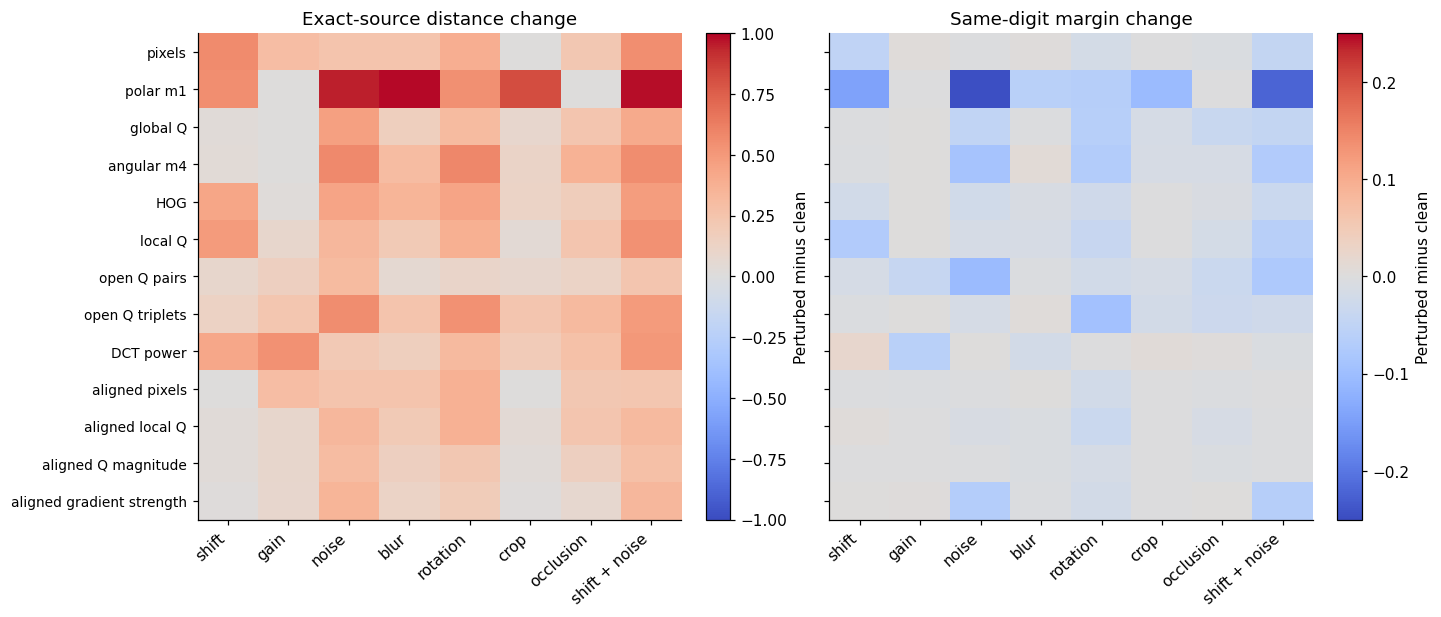

In [3]:
responses=pd.read_csv(OUT/'intervention_responses.csv') if (OUT/'intervention_responses.csv').exists() else run(SOURCE,OUT)['intervention_responses']
fig,axes=plt.subplots(1,2,figsize=(13,5.5))
configs=[('identity','target distance change','Exact-source distance change'),
         ('class','retrieval margin change','Same-digit margin change')]
for i,(ax,(endpoint,statistic,title)) in enumerate(zip(axes,configs)):
    data=responses[(responses.endpoint==endpoint)&(responses.statistic==statistic)]
    grid=data.pivot(index='method',columns='condition',values='change').loc[list(METHODS),list(CONDITIONS)[1:]]
    limit=1. if i==0 else .25
    im=ax.imshow(grid,cmap='coolwarm',vmin=-limit,vmax=limit,aspect='auto')
    ax.set_xticks(range(len(grid.columns)),grid.columns,rotation=42,ha='right')
    ax.set_yticks(range(len(METHODS)),METHODS if i==0 else [],fontsize=9)
    ax.set_title(title)
    fig.colorbar(im,ax=ax,label='Perturbed minus clean')
show('26_intervention_responses')

In [5]:
keep=['pixels','aligned pixels','local Q','aligned local Q','global Q','angular m4','DCT power']
z=responses.query("endpoint=='identity' and statistic=='target distance change' and condition in ['gain','shift','rotation']")
display(z[z.method.isin(keep)].pivot(index='method',columns='condition',values='change').round(4))
z=responses.query("endpoint=='class' and statistic=='retrieval margin change' and condition=='shift'")
display(z[z.method.isin(keep)][['method','change','low95','high95']].round(4))

condition,gain,rotation,shift
method,,,
DCT power,0.5355,0.3154,0.4292
aligned local Q,0.0887,0.3707,0.0278
aligned pixels,0.2903,0.3737,0.0000
angular m4,0.0000,0.5826,0.0363
global Q,0.0000,0.3117,0.0291
local Q,0.0887,0.3785,0.4880
pixels,0.2903,0.3868,0.5672


,method,change,low95,high95
39,pixels,-0.0502,-0.0646,-0.0360
41,global Q,-0.0035,-0.0082,0.0008
42,angular m4,-0.0042,-0.0092,0.0010
44,local Q,-0.0706,-0.0868,-0.0537
47,DCT power,0.0198,0.0098,0.0299
48,aligned pixels,-0.0029,-0.0064,0.0005
49,aligned local Q,0.0052,0.0021,0.0083


## Check the mechanisms on synthetic controls
On an open ramp, adding a constant leaves gradients and centered DCT power unchanged. Gain scales every gradient magnitude equally, preserving normalized global angular order. Local Q divides by gradient mass plus a reliability constant, so gain changes its damping. DCT power scales by the square of the gain, giving relative distance $(1-0.55^2)/(1+0.55^2)$. Contrast reversal flips the first angular moment and preserves the second and fourth. On a uniform ramp a quarter turn reverses Q, while fourth order is unchanged. These controls isolate specific effects. The MNIST perturbations can change several observable properties at once.

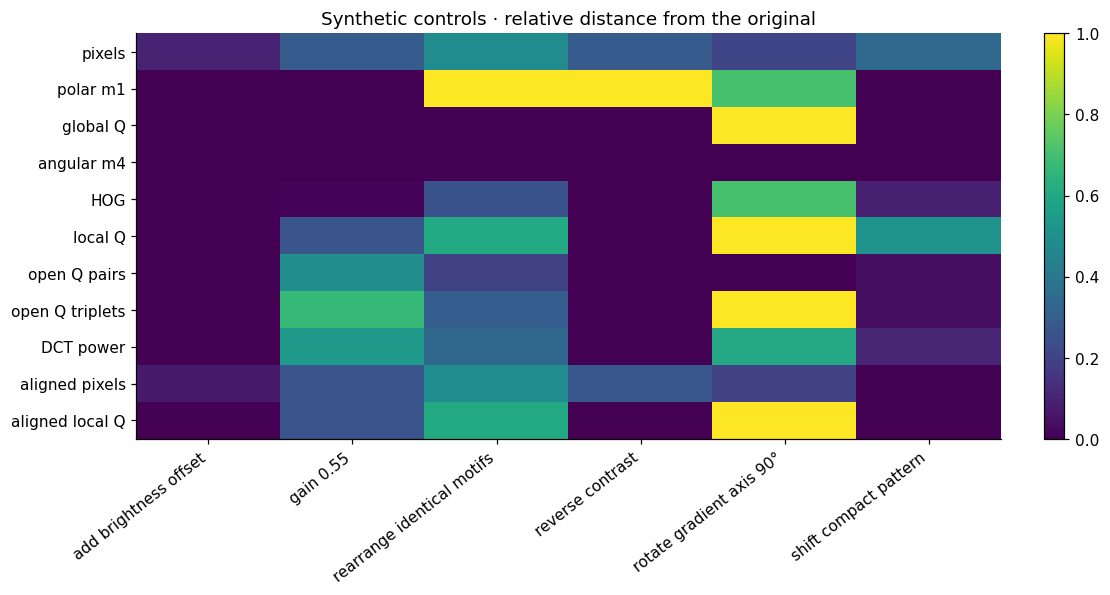

In [7]:
controls=pd.read_csv(OUT/'synthetic_controls.csv') if (OUT/'synthetic_controls.csv').exists() else run(SOURCE,OUT)['synthetic_controls']
grid=controls.pivot(index='method',columns='intervention',values='distance').loc[list(COMPONENTS)]
np.testing.assert_allclose(grid.loc['DCT power','gain 0.55'],(1-.55**2)/(1+.55**2),atol=1e-12)
np.testing.assert_allclose(grid.loc[['global Q','angular m4'],'gain 0.55'],0,atol=1e-12)
np.testing.assert_allclose(grid.loc[['global Q','angular m4','DCT power'],'reverse contrast'],0,atol=1e-12)
np.testing.assert_allclose(grid.loc['polar m1','reverse contrast'],1,atol=1e-12)
np.testing.assert_allclose(grid.loc['aligned pixels','shift compact pattern'],0,atol=1e-12)
np.testing.assert_allclose(grid.loc['global Q','rearrange identical motifs'],0,atol=1e-12)
fig,ax=plt.subplots(figsize=(10,5.3))
im=ax.imshow(grid,vmin=0,vmax=1,cmap='viridis',aspect='auto')
ax.set_xticks(range(len(grid.columns)),grid.columns,rotation=38,ha='right')
ax.set_yticks(range(len(grid)),grid.index)
ax.set_title('Synthetic controls · relative distance from the original')
fig.colorbar(im,ax=ax)
show('26_synthetic_controls')

The large gain response of DCT power is expected from its definition. It can be a useful amplitude measurement while providing poor evidence for gain-invariant identity. Zero global-Q response to motif rearrangement is equally informative about what the coordinate pools away. Both effects are visible in the profile even if a task-specific decision gives those components little weight.